# Use Human-in-the-Loop to Improve Your Data Science Copilot Results

### Free Generative AI Data Science Workshop

If you want to learn how to build AI Agents that perform Data Science, Business Intelligence, Churn Modeling, Time Series Forecasting, and more, [register for my next free AI for Data Scientists workshop here.](https://learn.business-science.io/ai-register)


# Table of Contents

1. [Introduction](#introduction)
2. [What is Human-in-the-Loop?](#what-is-human-in-the-loop)
3. [What is Data Science Copilot?](#what-is-data-science-copilot)
4. [Example: Using Human-in-the-Loop to Improve Data Science Copilot Results for Feature Engineering](#example-using-human-in-the-loop-to-improve-data-science-copilot-results-for-feature-engineering)
    1. [Load Libraries](#load-libraries)
    2. [Setup AI and Logging](#setup-ai-and-logging)
    3. [Load a Dataset](#load-a-dataset)
    4. [Create The Agent](#create-the-agent)
    5. [Invoke the Feature Engineering Agent with Human-In-The-Loop](#invoke-the-feature-engineering-agent-with-human-in-the-loop)
    6. [Human Review](#human-review)
    7. [Respond to eliminate conversion of Boolean values](#respond-to-eliminate-conversion-of-boolean-values)
    8. [Re-Review](#re-review)
    9. [Accept the modifications and proceed with the execution](#accept-the-modifications-and-proceed-with-the-execution)
5. [Free Generative AI Data Science Workshop](#free-generative-ai-data-science-workshop)

# Introduction

### What is Human-in-the-Loop?

Human-in-the-Loop is a concept where humans are involved in the decision-making process of AI models. The idea is that humans can provide feedback to AI models to improve their performance. This is especially useful in the case of AI models that are not perfect and need human intervention to improve their performance.

### What is Data Science Copilot (and how does Human-in-the-Loop Help)?

Data Science Copilot is a tool that helps data scientists write code faster and more efficiently. It is an AI-powered tool that provides code suggestions and auto-completion for data science tasks. Data Science Copilot can help data scientists complete common data science tasks faster.

**Human-in-the-Loop gives Data Scientists an opportunity to review the AI's plan before it executes code** to process the data or create machine learning models. This is important because the AI may not always provide the best suggestions, and human intervention can help improve the results.


## Example: Using Human-in-the-Loop to Improve Data Science Copilot Results for Feature Engineering

In this example, we will use Human-in-the-Loop to improve the results of Data Science Copilot for feature engineering. Feature engineering is an important step in the data science process, where we create new features and process existing features in data to improve the performance of machine learning models.

### Load Libraries

In [1]:
from langchain_openai import ChatOpenAI
from langgraph.types import Command

import os
import yaml
import pandas as pd
from pprint import pprint
from IPython.display import Markdown

from ai_data_science_team.agents import FeatureEngineeringAgent

### Setup AI and Logging

This section of code sets up the LLM inputs and the logging information. Logging is used to store AI-generated code and files during the AI Data Science Teams processing of files. 

*Important Note:* This example uses OpenAI's API. But any LLM can be used such as Anthropic or local LLMs with Ollama.

In [8]:
MODEL    = "gpt-4o-mini"
LOG      = True
LOG_PATH = os.path.join(os.getcwd(), "logs/")

os.environ["OPENAI_API_KEY"] = yaml.safe_load(open('../credentials.yml'))['openai']

llm = ChatOpenAI(model = MODEL)
llm

ChatOpenAI(client=<openai.resources.chat.completions.Completions object at 0x7f81e01a2890>, async_client=<openai.resources.chat.completions.AsyncCompletions object at 0x7f81c154fa90>, root_client=<openai.OpenAI object at 0x7f8230f9a6e0>, root_async_client=<openai.AsyncOpenAI object at 0x7f81e01a28c0>, model_name='gpt-4o-mini', model_kwargs={}, openai_api_key=SecretStr('**********'))

In [9]:
df = pd.read_csv("https://raw.githubusercontent.com/business-science/ai-data-science-team/refs/heads/master/data/churn_data.csv")
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


### Create The Agent

Run this code to create the agent with `FeatureEngineeringAgent()`.

**Important:** In this step we will set `human_in_the_loop=True` to enable human-in-the-loop. This will allow us to review the AI's plan before it executes the code.

Notice that the agent's graph now includes a new node called "Human Review". This node represents the step where the human reviews the AI's plan before it executes the code.

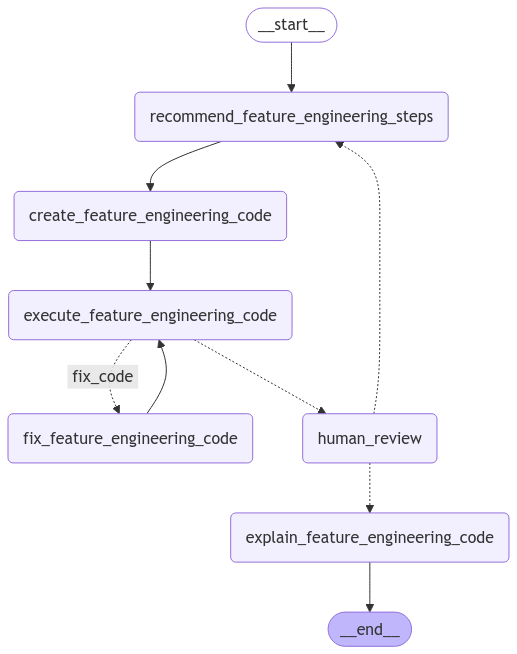

In [10]:
feature_engineering_agent = FeatureEngineeringAgent(
    model = llm, 
    log=LOG, 
    log_path=LOG_PATH, 
    human_in_the_loop=True,
)

feature_engineering_agent

### Invoke the Feature Engineering Agent with Human-In-The-Loop

In [11]:
# Invoke the Feature Engineering Agent with Human-In-The-Loop
config = {"configurable": {"thread_id": "1"}}

feature_engineering_agent.invoke_agent(
    data_raw=df,
    user_instructions="Please perform feature engineering on the dataset.",
    target_variable="Churn",
    max_retries=3,
    config=config,
)

---FEATURE ENGINEERING AGENT----
    * RECOMMEND FEATURE ENGINEERING STEPS
    * CREATE FEATURE ENGINEERING CODE
      File saved to: /Users/mdancho/Desktop/course_code/ai-data-science-team/logs/feature_engineer.py
    * EXECUTING AGENT CODE
    * HUMAN REVIEW


The agent pauses at "HUMAN REVIEW" node. The agent is waiting for the human to provide the required information.

This is how to perform the review:

### Expose the AI's Plan from the interruped state

First, lets expose the AI's feature engineering plan by running the following code:

In [12]:
# Human Review
state = feature_engineering_agent._compiled_graph.get_state(config=config)

Markdown(state.tasks[-1].interrupts[-1].value)

Are the following feature engineering instructions correct? (Answer 'yes' or provide modifications)
# Recommended Feature Engineering Steps:
1. **Convert Data Types:**
   - Convert `TotalCharges` from `object` to `float64` since it represents numeric values.

2. **Remove Unique Features:**
   - Remove `customerID` as it has unique values equal to the size of the dataset (7043 unique values).

3. **Remove Constant Features:**
   - Check for any constant features with the same value across all rows and remove them if found (none identified in the provided dataset).

4. **Handle High Cardinality Categorical Features:**
   - Identify categorical features with high cardinality (more than 5% of the dataset) and encode them by grouping infrequent values into an "other" category. For this dataset, this applies to columns like `PaymentMethod`, but since it has only 4 unique values, no grouping is necessary.

5. **One-Hot Encoding:**
   - Apply OneHotEncoding to categorical features: `gender`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaperlessBilling`, and `PaymentMethod`.

6. **Leave Numeric Features Untransformed:**
   - Leave `SeniorCitizen`, `tenure`, `MonthlyCharges`, and the newly converted `TotalCharges` as they are since they are already numeric.

7. **Create Datetime Features:**
   - Since there are no datetime columns present in the dataset, this step can be skipped.

8. **Encode Target Variable:**
   - Encode the `Churn` target variable using LabelEncoding, as it is categorical with two unique values.

9. **Convert Boolean Values:**
   - Convert the `SeniorCitizen` column (which is binary) to integer values (0/1). This step is typically done after encoding categorical variables, but since it is already represented as integers, no further action is needed.

10. **Analyze for Additional Steps:**
    - Review the dataset for any additional feature engineering opportunities based on context or domain knowledge, such as interaction features or aggregating certain characteristics (e.g., tenure groups).

11. **Final Review:**
    - Conduct a final review to ensure all necessary features have been engineered and that the data is ready for modeling.

12. **No Additional Steps Required:**
    - If after analysis no further enhancements or modifications are deemed necessary, state that no additional steps are required.

```python
# Disclaimer: This function was generated by AI. Please review before using.
# Agent Name: feature_engineering_agent
# Time Created: 2025-01-11 22:08:27

def feature_engineer(data_raw):
    import pandas as pd
    import numpy as np
    from sklearn.preprocessing import OneHotEncoder, LabelEncoder



    # Step 1: Convert TotalCharges to float
    data_raw['TotalCharges'] = pd.to_numeric(data_raw['TotalCharges'], errors='coerce')

    # Step 2: Remove unique feature
    data_raw = data_raw.drop(columns=['customerID'])

    # Step 3: Remove constant features (none identified)

    # Step 4: Handle high cardinality categorical features (none need grouping here)

    # Step 5: One-hot encoding categorical features
    categorical_features = [
        'gender', 'Partner', 'Dependents', 'PhoneService', 
        'MultipleLines', 'InternetService', 'OnlineSecurity', 
        'OnlineBackup', 'DeviceProtection', 'TechSupport', 
        'StreamingTV', 'StreamingMovies', 'Contract', 
        'PaperlessBilling', 'PaymentMethod'
    ]
    
    # One-hot encode the categorical features
    data_encoded = pd.get_dummies(data_raw, columns=categorical_features, drop_first=True)

    # Step 6: Leave numeric features untransformed (already numeric)
    # Numeric features: SeniorCitizen, tenure, MonthlyCharges, TotalCharges

    # Step 7: Create datetime features (none present)

    # Step 8: Encode target variable 'Churn'
    label_encoder = LabelEncoder()
    data_encoded['Churn'] = label_encoder.fit_transform(data_encoded['Churn'])

    # Step 9: Convert SeniorCitizen to integer values (0/1)
    # This step is already done as SeniorCitizen is already int64

    # Step 10: Analyze for additional steps (none identified)

    # Step 11: Final review (all steps completed)

    # Step 12: No additional steps required
    return data_encoded
```

Check the data post transformation by running the following code:

In [13]:
feature_engineering_agent.get_data_engineered()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,0,True,True,True,True,False,...,False,True,False,True,True,False,True,False,False,True
7039,0,72,103.20,7362.90,0,False,True,True,True,False,...,False,True,False,True,True,False,True,True,False,False
7040,0,11,29.60,346.45,0,False,True,True,False,True,...,False,False,False,False,False,False,True,False,True,False
7041,1,4,74.40,306.60,1,True,True,False,True,False,...,False,False,False,False,False,False,True,False,False,True


We can either respond "Yes" if the plan looks good or we can request modifications. If we respond "Yes" the agent will continue to execute the code. If we request modifications, the agent will go back to the recommend feature engineering steps node and revise the plan according to your instructions.

### Let's respond requesting to convert Boolean columns to integer. 

We'll use `Command()` to `resume` the agent with our request to convert Boolean values to integers after one hot encoding. 

In [ ]:
# Respond to eliminate coversion of Boolean values

feature_engineering_agent.invoke(Command(resume="Make sure to convert Boolean columns to integers. One hot encoded columns are being left as Boolean."), config=config)

The Feature Engineering Agent has went back to the "Recommend Feature Engineering Steps" node and revised the plan according to our instructions.

We can review the revised plan to make sure our request was implemented correctly.

In [20]:
# Re-Review: Now Booleans will not be converted
state = feature_engineering_agent._compiled_graph.get_state(config=config)
Markdown(state.tasks[-1].interrupts[-1].value)

Are the following feature engineering instructions correct? (Answer 'yes' or provide modifications)
# Recommended Feature Engineering Steps:
1. **Convert Data Types:**
   - Convert `TotalCharges` from `object` to `float64` since it represents numeric values.

2. **Remove Unique Features:**
   - Remove `customerID` as it has unique values equal to the size of the dataset (7043 unique values).

3. **Remove Constant Features:**
   - Check for any constant features with the same value across all rows and remove them if found (none identified in the provided dataset).

4. **Handle High Cardinality Categorical Features:**
   - Identify categorical features with high cardinality (more than 5% of the dataset) and encode them by grouping infrequent values into an "other" category. For this dataset, no such features require grouping.

5. **One-Hot Encoding:**
   - Apply OneHotEncoding to categorical features: `gender`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaperlessBilling`, and `PaymentMethod`.

6. **Leave Numeric Features Untransformed:**
   - Leave `SeniorCitizen`, `tenure`, `MonthlyCharges`, and the newly converted `TotalCharges` as they are since they are already numeric.

7. **Create Datetime Features:**
   - Since there are no datetime columns present in the dataset, this step can be skipped.

8. **Encode Target Variable:**
   - Encode the `Churn` target variable using LabelEncoding, as it is categorical with two unique values.

9. **Convert Boolean Values to Integers:**
   - Convert any Boolean columns (e.g., `SeniorCitizen`, which is already in integer format) to integer values (0/1) after the OneHotEncoding step, ensuring they are properly represented.

10. **Analyze for Additional Steps:**
    - Review the dataset for any additional feature engineering opportunities based on context or domain knowledge, such as interaction features or aggregating certain characteristics (e.g., tenure groups).

11. **Final Review:**
    - Conduct a final review to ensure all necessary features have been engineered and that the data is ready for modeling.

12. **No Additional Steps Required:**
    - If after analysis no further enhancements or modifications are deemed necessary, state that no additional steps are required.

```python
# Disclaimer: This function was generated by AI. Please review before using.
# Agent Name: feature_engineering_agent
# Time Created: 2025-01-11 22:10:00

def feature_engineer(data_raw):
    import pandas as pd
    import numpy as np
    from sklearn.preprocessing import OneHotEncoder, LabelEncoder



    # Step 1: Convert Data Types
    data_raw['TotalCharges'] = pd.to_numeric(data_raw['TotalCharges'], errors='coerce')
    
    # Step 2: Remove Unique Features
    data_raw = data_raw.drop(columns=['customerID'])
    
    # Step 3: Remove Constant Features
    # (No constant features found, skip this step)
    
    # Step 4: Handle High Cardinality Categorical Features
    # (No high cardinality features found that require grouping, skip this step)

    # Step 5: One-Hot Encoding
    categorical_features = [
        'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
        'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
        'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
        'PaperlessBilling', 'PaymentMethod'
    ]
    
    # Apply OneHotEncoder
    encoder = OneHotEncoder(sparse=False, drop='first')
    encoded_features = encoder.fit_transform(data_raw[categorical_features])
    
    # Create a DataFrame with encoded features
    encoded_df = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_features))
    
    # Concatenate the encoded features with the original DataFrame (excluding original categorical features)
    data_engineered = pd.concat([data_raw.drop(columns=categorical_features), encoded_df], axis=1)
    
    # Step 6: Leave Numeric Features Untransformed
    # (Numeric features already untouched, skip this step)

    # Step 7: Create Datetime Features
    # (No datetime columns present, skip this step)
    
    # Step 8: Encode Target Variable
    label_encoder = LabelEncoder()
    data_engineered['Churn'] = label_encoder.fit_transform(data_engineered['Churn'])
    
    # Step 9: Convert Boolean Values to Integers
    # SeniorCitizen is already in integer format, no conversion needed
    
    # Step 10: Analyze for Additional Steps
    # (No additional features identified, skip this step)
    
    # Step 11: Final Review
    # (No issues found)
    
    # Step 12: No Additional Steps Required
    return data_engineered
```

Inspect the data post transformation by running the following code:

In [21]:
feature_engineering_agent.get_data_engineered()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0,34,56.95,1889.50,0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0,2,53.85,108.15,1,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,0,45,42.30,1840.75,0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0,2,70.70,151.65,1,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,0,1.0,1.0,1.0,1.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0
7039,0,72,103.20,7362.90,0,0.0,1.0,1.0,1.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0
7040,0,11,29.60,346.45,0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
7041,1,4,74.40,306.60,1,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


We can see that the agent is now skipping the conversion of Boolean values to integers per user instructions.

### Accept the modifications and proceed with the explanation

In [22]:
# Accept modifications to feature engineering instructions
feature_engineering_agent.invoke(Command(resume="Yes"), config=config)

    * HUMAN REVIEW
    * EXPLAIN AGENT CODE


{'messages': [AIMessage(content="# Feature Engineering Agent:\n\n The `feature_engineer` function performs several key steps in feature engineering on a given dataset. Here's a clear and concise breakdown of the steps involved:\n\n1. **Convert Data Types**: It converts the `TotalCharges` column to a numeric type, handling any conversion errors by setting them to `NaN`.\n\n2. **Remove Unique Features**: The function drops the `customerID` column, which is a unique identifier and not useful for predictive modeling.\n\n3. **Remove Constant Features**: This step checks for constant features, but none are found, so it is skipped.\n\n4. **Handle High Cardinality Categorical Features**: It checks for high cardinality features that may require grouping but finds none, thus skipping this step as well.\n\n5. **One-Hot Encoding**: A list of categorical features is defined, and One-Hot Encoding is applied to these features using `OneHotEncoder`, creating binary columns for each category while drop

In [23]:
feature_engineering_agent.get_data_engineered()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0,34,56.95,1889.50,0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0,2,53.85,108.15,1,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,0,45,42.30,1840.75,0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0,2,70.70,151.65,1,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,0,1.0,1.0,1.0,1.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0
7039,0,72,103.20,7362.90,0,0.0,1.0,1.0,1.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0
7040,0,11,29.60,346.45,0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
7041,1,4,74.40,306.60,1,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [24]:
feature_engineering_agent.get_feature_engineer_function(markdown=True)

```python
# Disclaimer: This function was generated by AI. Please review before using.
# Agent Name: feature_engineering_agent
# Time Created: 2025-01-11 22:10:00

def feature_engineer(data_raw):
    import pandas as pd
    import numpy as np
    from sklearn.preprocessing import OneHotEncoder, LabelEncoder



    # Step 1: Convert Data Types
    data_raw['TotalCharges'] = pd.to_numeric(data_raw['TotalCharges'], errors='coerce')
    
    # Step 2: Remove Unique Features
    data_raw = data_raw.drop(columns=['customerID'])
    
    # Step 3: Remove Constant Features
    # (No constant features found, skip this step)
    
    # Step 4: Handle High Cardinality Categorical Features
    # (No high cardinality features found that require grouping, skip this step)

    # Step 5: One-Hot Encoding
    categorical_features = [
        'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
        'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
        'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
        'PaperlessBilling', 'PaymentMethod'
    ]
    
    # Apply OneHotEncoder
    encoder = OneHotEncoder(sparse=False, drop='first')
    encoded_features = encoder.fit_transform(data_raw[categorical_features])
    
    # Create a DataFrame with encoded features
    encoded_df = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_features))
    
    # Concatenate the encoded features with the original DataFrame (excluding original categorical features)
    data_engineered = pd.concat([data_raw.drop(columns=categorical_features), encoded_df], axis=1)
    
    # Step 6: Leave Numeric Features Untransformed
    # (Numeric features already untouched, skip this step)

    # Step 7: Create Datetime Features
    # (No datetime columns present, skip this step)
    
    # Step 8: Encode Target Variable
    label_encoder = LabelEncoder()
    data_engineered['Churn'] = label_encoder.fit_transform(data_engineered['Churn'])
    
    # Step 9: Convert Boolean Values to Integers
    # SeniorCitizen is already in integer format, no conversion needed
    
    # Step 10: Analyze for Additional Steps
    # (No additional features identified, skip this step)
    
    # Step 11: Final Review
    # (No issues found)
    
    # Step 12: No Additional Steps Required
    return data_engineered
```

### Free Generative AI Data Science Workshop

If you want to learn how to build AI Agents that perform Data Science, Business Intelligence, Churn Modeling, Time Series Forecasting, and more, [register for my next free AI for Data Scientists workshop here.](https://learn.business-science.io/ai-register)